# Transported separatrix-connectivity barycenter reconstruction

This notebook reconstructs MSC-like barycenter topology from a saved PFGW bundle.

**Method.** Infer topology from transported exact adjacency and transported separatrix-local connectivity. Use `separatrixID` as the authoritative source of chain provenance. Soft paths remain inside one fixed recorded separatrix ID. Overlapping separatrices are retained without merging identities. `C_center` is used only for optional post-hoc comparison after the graph and all reconstruction parameters are fixed.

This notebook does not rerun the PFGW solver and does not claim an exact Morse–Smale complex without a later scalar-field realization.


## Configuration

Defaults are deterministic exploration settings, not theoretically optimal values. Reconstruction artifacts are written under a new timestamped directory and do not overwrite previous reconstructions.


In [1]:
import importlib
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import Markdown, display

from lib.barycenter_io import load_barycenter_bundle

import lib.msc_barycenter_reconstruction_separatrix as msc_barycenter_reconstruction_separatrix
importlib.reload(msc_barycenter_reconstruction_separatrix)
from lib.msc_barycenter_reconstruction_separatrix import (
    ReconstructionConfig,
    TERMINOLOGY_VERSION,
    validate_barycenter_bundle,
    decode_barycenter_nodes,
    compute_transported_separatrix_connectivity,
    construct_candidate_edge_table,
    infer_target_component_count,
    build_maximum_support_forest,
    augment_consensus_edges,
    local_repair_topology,
    validate_reconstructed_topology,
    run_q_hop_sensitivity,
    run_sampling_mode_sensitivity,
    compare_posthoc_baselines,
    build_evidence_density_field,
    route_graph_through_density,
    save_reconstruction_bundle,
    load_graph_pickle,
    verify_reloaded_topology,
    run_synthetic_separatrix_tests,
    graph_objective_components,
)

PROJECT_ROOT = Path(".").resolve()
DATA_KEYWORD = "synthetic"
# DATA_KEYWORD = "VortexStreet"
config = ReconstructionConfig(
    run_name=f"{DATA_KEYWORD}_latest",
    reconstruction_name="transported_separatrix_connectivity",
    hop_decay_q=0.10,
    max_soft_hops=2,
    enable_density_routing=False,
    planarity_mode="hard",
)
BUNDLE_DIR = config.resolve_bundle_dir(PROJECT_ROOT)
OUTPUT_DIR, FIGURES_DIR = config.resolve_output_dirs(PROJECT_ROOT, create=True)
pd.DataFrame(
    [{"Setting": k, "Resolved value": v} for k, v in config.resolved_dict(PROJECT_ROOT).items()]
).head(20)


,Setting,Resolved value
0,run_name,synthetic_latest
1,reconstruction_name,transported_separatrix_connectivity
2,bundle_dir,C:\Users\mingz\desktop\MSCBarycenter\results\b...
3,random_seed,20260808
4,separatrix_id_attribute,separatrixID
5,separatrix_id_delimiter,","
6,missing_separatrix_id_policy,error
7,strict_separatrix_validation,True
8,allow_degree_based_chain_fallback,False
9,strict_validation,True


## Terminology used in this notebook

| Term | Meaning |
| --- | --- |
| Direct-adjacency support | Conditional consistency of exact input adjacency |
| Separatrix-connectivity support | Conditional consistency of nearby connectivity along one fixed recorded separatrix |
| Pair coverage | Amount of weighted correspondence information available for both endpoints |
| Direct-adjacency evidence | Coverage-weighted exact adjacency evidence |
| Separatrix-connectivity evidence | Coverage-weighted separatrix-local evidence |
| Soft-extension evidence | Evidence contributed by nearby-but-not-direct pairs |
| Connectivity-selection score | Explicit score used to rank candidate barycenter edges |

$$
E_{ij}^{\mathrm{direct}} = O_{ij} S_{ij}^{\mathrm{direct}}, \qquad
E_{ij}^{\mathrm{sep}} = O_{ij} S_{ij}^{\mathrm{sep}}.
$$

- High conditional support with low coverage is consistent but scarce evidence.
- High coverage with low direct support is evidence against exact adjacency.
- High separatrix support with low direct support indicates likely sampling mismatch along a shared separatrix.
- Support must not be interpreted without coverage.

Shared-separatrix membership is **not** transitive. Soft affinity paths must retain one fixed separatrix ID:

```text
u -- v -- w
edge (u, v): separatrixID = "0"
edge (v, w): separatrixID = "1"
```

Then $\Sigma(u)=\{0\}$, $\Sigma(v)=\{0,1\}$, $\Sigma(w)=\{1\}$, so $u$ and $w$ receive zero separatrix-local affinity even though their unrestricted hop distance is two.

Hop decay is tolerant to small sampling mismatches but is not completely invariant to nonuniform sampling density.


## Load and validate the barycenter bundle

Aligned inputs `Ts[s]`, `Cs[s]`, `Ys[s]`, `ps[s]`, `lambdas[s]`, `nodes_list[s]`, `Gs[s]`, and `mesh_ids[s]` are required. If couplings, graphs, or trustworthy node orderings are unavailable, reconstruction stops. There is no silent `C_center` fallback. A held-out seed is excluded from reconstruction and may appear only as a labeled post-hoc baseline.


In [2]:
bundle = load_barycenter_bundle(BUNDLE_DIR)
validation = validate_barycenter_bundle(bundle, strict_validation=config.strict_validation)
input_node_orders = validation.input_node_orders
print(
    f"Loaded {validation.n_inputs} inputs, n_center={validation.n_center}, "
    f"held_out_seed={validation.has_held_out_seed}, exclude_seed={validation.exclude_seed}"
)
for warning in validation.warnings:
    print("warning:", warning)
display(Markdown(f"`terminology_version = {TERMINOLOGY_VERSION}`"))


Loaded 9 inputs, n_center=435, held_out_seed=True, exclude_seed=True


`terminology_version = 4`

## Decode and inspect barycenter nodes


In [3]:
decoded = decode_barycenter_nodes(bundle, config)
nodes_df = decoded.dataframe.copy()
display(nodes_df.head())
print(
    "coordinates:", decoded.has_coordinates,
    "scalar:", decoded.has_scalar,
    "types:", decoded.has_types,
)
print(
    "effective constraints:",
    decoded.effective_type_constraint_mode,
    decoded.effective_scalar_order_constraint_mode,
    decoded.effective_planarity_mode,
)
nodes_df.to_csv(OUTPUT_DIR / "decoded_nodes.csv", index=False)


,node_id,x,y,z,scalar_normalized,scalar_value,morse_type,type_confidence,mass,coordinate_source,scalar_source,type_source
0,0,0.000000,0.000000,0.0,0.917458,0.504326,0,1.0,0.001233,features,features,features
1,1,0.000000,0.021297,0.0,0.928781,0.512632,1,1.0,0.001953,features,features,features
2,2,0.020114,0.001183,0.0,0.928781,0.512632,1,1.0,0.001953,features,features,features
3,3,0.210949,0.217092,0.0,0.126504,-0.075852,0,1.0,0.001744,features,features,features
4,4,0.246817,0.226948,0.0,0.229636,-0.000203,-1,1.0,0.003414,features,features,features


coordinates: True scalar: True types: True
effective constraints: soft soft hard


## Validate recorded separatrix annotations

Every input edge `separatrixID` is parsed as a set of IDs. A value such as `"0,1,3"` means the edge belongs independently to separatrices `"0"`, `"1"`, and `"3"`.


,input_index,node_count,edge_count,unique_separatrix_id_count,missing_separatrix_id_count,malformed_value_count,nodes_with_no_incident_id,multi_id_edge_fraction,maximum_ids_on_one_edge,disconnected_per_id_subgraph_count,non_path_like_per_id_subgraph_count,sampled_edge_length_median,sampled_edge_length_cv,fraction_edges_substantially_shorter_than_median
0,0,407,415,46,0,0,0,0.036145,2,0,0,0.02,0.184771,0.038554
1,1,433,442,56,0,0,0,0.036199,3,0,0,0.02,0.229646,0.061086
2,2,425,434,52,0,0,0,0.032258,3,0,0,0.02,0.208162,0.052995
3,3,410,418,48,0,0,0,0.026316,2,0,0,0.02,0.201693,0.050239
4,4,423,432,56,0,0,0,0.020833,2,0,0,0.02,0.213762,0.055556
5,5,413,421,48,0,0,0,0.035629,3,0,0,0.02,0.202669,0.049881
6,6,410,418,48,0,0,0,0.016746,2,0,0,0.02,0.207616,0.047847
7,7,435,444,58,0,0,0,0.033784,3,0,0,0.02,0.236044,0.067568
8,8,424,433,54,0,0,0,0.066975,3,0,0,0.02,0.217511,0.053118


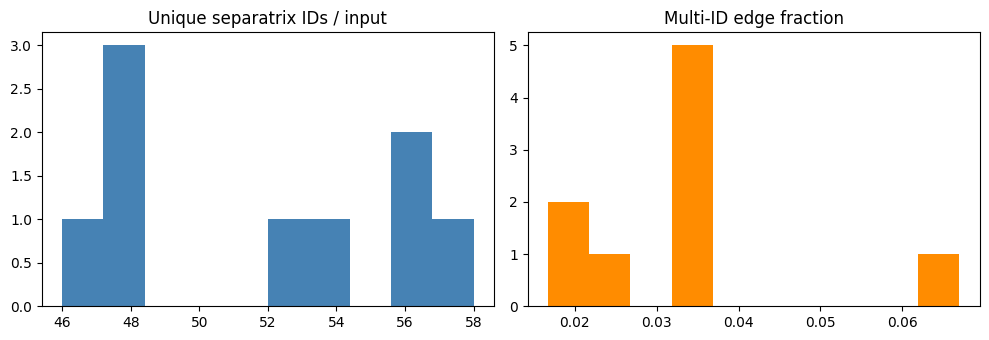

In [4]:
# Annotation diagnostics are computed during transport; run a lightweight preview first.
from lib.msc_barycenter_reconstruction_separatrix import (
    build_separatrix_membership,
    diagnose_separatrix_annotations,
)

preview_rows = []
for s, graph in enumerate(bundle["Gs"]):
    membership = build_separatrix_membership(
        graph,
        attribute=config.separatrix_id_attribute,
        delimiter=config.separatrix_id_delimiter,
        strict=config.strict_separatrix_validation,
        missing_policy=config.missing_separatrix_id_policy,
    )
    annotation, subgraph_df, _, _, sampling = diagnose_separatrix_annotations(
        graph, s, membership
    )
    preview_rows.append(annotation)
preview_df = pd.DataFrame(preview_rows)
display(preview_df)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(preview_df["unique_separatrix_id_count"], bins=10, color="steelblue")
axes[0].set_title("Unique separatrix IDs / input")
axes[1].hist(preview_df["multi_id_edge_fraction"], bins=10, color="darkorange")
axes[1].set_title("Multi-ID edge fraction")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "separatrix_annotation_preview.png", dpi=140)
plt.show()


## Build direct adjacency and separatrix-local affinities

Direct adjacency is exact binary adjacency. Separatrix-local connectivity affinity uses hop decay
$K(u,v)=q^{d_{\mathrm{sep}}(u,v)-1}$ for $1 \le d_{\mathrm{sep}} \le H$ inside one fixed separatrix ID.


## Transport connectivity through PFGW couplings

Conditional supports answer different questions from pair coverage. Seed graphs held out of the barycenter are never included.


,value
n_inputs,9
n_center,435
lambda_sum,1.0
q,0.1
max_soft_hops,2
affinity_mode,separatrix_hop_decay
covered_pair_count,93961
mean_conditional_direct_adjacency_support,0.004602
mean_conditional_separatrix_connectivity_support,0.005044
mean_pair_coverage,0.963382


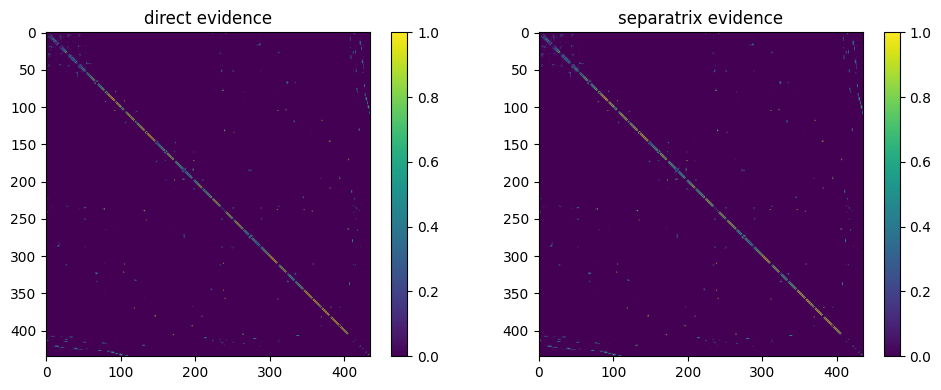

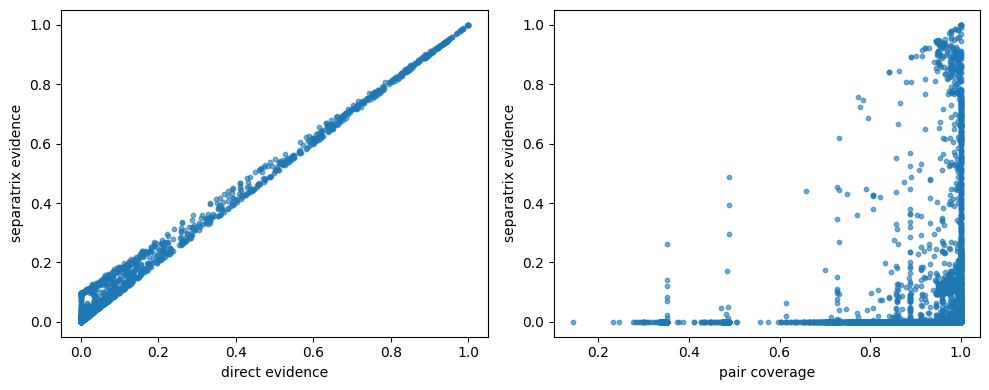

In [5]:
transported = compute_transported_separatrix_connectivity(
    bundle, input_node_orders, config
)
for warning in transported.warnings:
    print("warning:", warning)
display(pd.Series(transported.diagnostics, name="value").to_frame())

# Conditional support S is an intermediate for evidence E = O * S; show E only.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
matrices = [
    ("direct evidence", transported.direct_adjacency_evidence),
    ("separatrix evidence", transported.separatrix_connectivity_evidence),
]
for ax, (title, matrix) in zip(axes.ravel(), matrices):
    im = ax.imshow(np.nan_to_num(matrix, nan=0.0), cmap="viridis")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "transported_connectivity_heatmaps.png", dpi=140)
plt.show()

upper = np.triu(transported.pair_is_covered, 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(
    transported.direct_adjacency_evidence[upper],
    transported.separatrix_connectivity_evidence[upper],
    s=10,
    alpha=0.6,
)
axes[0].set_xlabel("direct evidence")
axes[0].set_ylabel("separatrix evidence")
axes[1].scatter(
    transported.pair_coverage[upper],
    transported.separatrix_connectivity_evidence[upper],
    s=10,
    alpha=0.6,
)
axes[1].set_xlabel("pair coverage")
axes[1].set_ylabel("separatrix evidence")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "support_coverage_scatter.png", dpi=140)
plt.show()


## Visualize evidence as thresholded edge overlays

Conditional support $S$ is an intermediate for evidence $E=O\cdot S$. Before candidate selection and skeleton construction, inspect the transported evidence matrices geometrically: draw every barycenter pair whose evidence exceeds a notebook-local threshold, laid out with the decoded node coordinates.

| Matrix | Role |
| --- | --- |
| Direct-adjacency evidence | Coverage-weighted exact adjacency |
| Separatrix-connectivity evidence | Coverage-weighted separatrix-local connectivity |

Edge color and transparency follow a sequential colormap of the retained weights. `MIN_EDGE_THRESHOLD` and `MIN_TRANSPARENCY` live only in this section for quick tuning and are not reconstruction config.


figure axes=3 (expect 4 = 2 plots + 2 colorbars); cmaps=['blues_dark_edges']


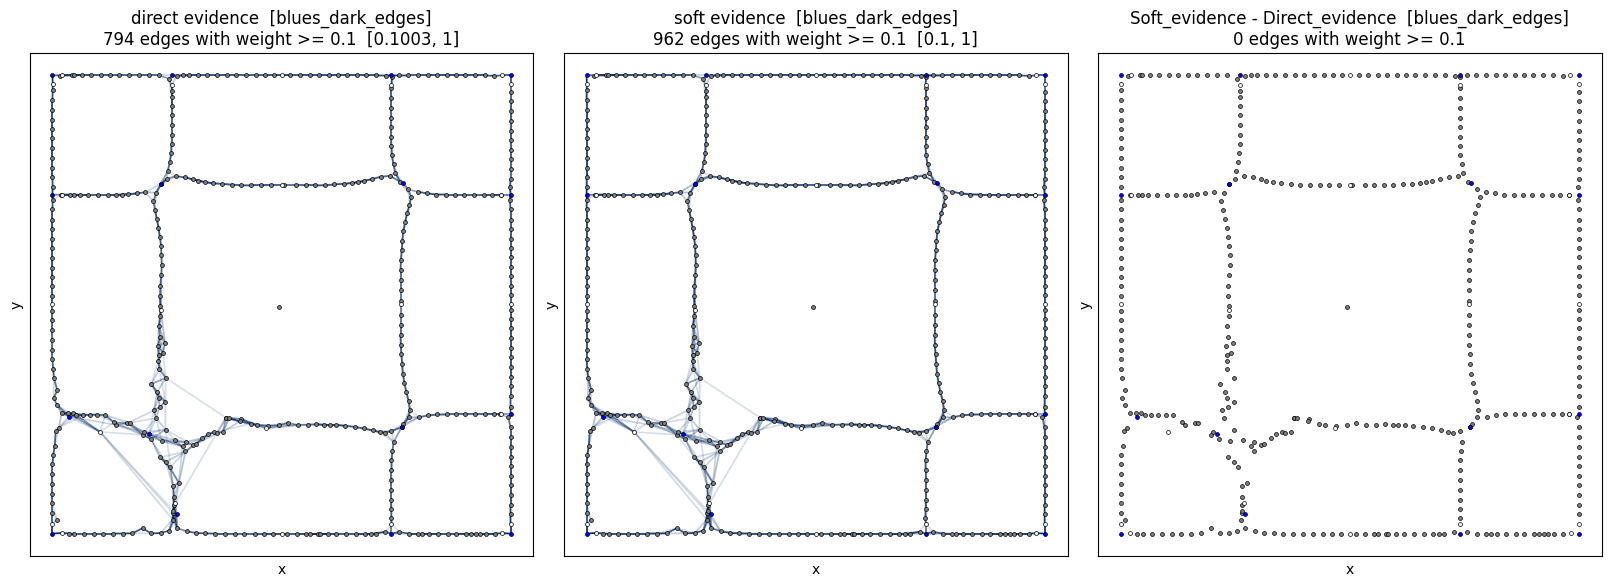

,view,edge_count,w_min,w_max,cmap
0,direct evidence,794,0.100326,1.0,blues_dark_edges
1,soft evidence,962,0.100024,1.0,blues_dark_edges
2,Soft_evidence - Direct_evidence,0,NaN,NaN,blues_dark_edges


In [10]:
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from lib.msc_plotting import draw_msc_nodes, set_barycenter_axes_limits

# Intermediate visualization knobs (notebook-local; not ReconstructionConfig)
MIN_EDGE_THRESHOLD = 0.10
MIN_TRANSPARENCY = min(1.0, MIN_EDGE_THRESHOLD * 1.50)


def draw_barycenter_weighted_edges(
    weight_matrix,
    min_edge_threshold,
    min_transparency,
    *,
    nodes_df,
    title=None,
    cmap=None,
    ax=None,
    figsize=(8, 7),
    edge_width=1.25,
    node_size=8,
):
    """Draw all barycenter pairs with weight >= threshold using node coordinates.

    Default colormap is a truncated Blues map (no near-white samples), not viridis.
    Each call adds a colorbar for the retained edge weights on the target axes.
    """
    W = np.asarray(weight_matrix, dtype=float)
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError(f"weight_matrix must be square; got shape {W.shape}.")
    min_transparency = float(np.clip(min_transparency, 0.0, 1.0))
    n = W.shape[0]

    # IMPORTANT: build the colormap inside this function.
    # Truncated Blues avoids white/yellow washout on a white background.
    if cmap is None:
        blues = plt.get_cmap("Blues")
        cmap_obj = LinearSegmentedColormap.from_list(
            "blues_dark_edges",
            blues(np.linspace(0.99, 1.00, 256)),
        )
    elif isinstance(cmap, str):
        cmap_obj = plt.get_cmap(cmap)
    else:
        cmap_obj = cmap

    pos = {
        int(row.node_id): np.array([float(row.x), float(row.y)], dtype=float)
        for row in nodes_df.itertuples(index=False)
        if np.isfinite(row.x) and np.isfinite(row.y)
    }
    if len(pos) != n:
        raise ValueError(
            f"Need finite (x, y) for all {n} barycenter nodes; got {len(pos)}."
        )

    iu, ju = np.triu_indices(n, k=1)
    weights = W[iu, ju]
    keep = np.isfinite(weights) & (weights >= float(min_edge_threshold))
    iu, ju, weights = iu[keep], ju[keep], weights[keep]

    created_fig = ax is None
    if created_fig:
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    else:
        fig = ax.figure

    if weights.size:
        w_min = float(weights.min())
        w_max = float(weights.max())
        if w_max > w_min:
            t = (weights - w_min) / (w_max - w_min)
        else:
            t = np.ones(len(weights), dtype=float)

        # Color from the sequential map; alpha also scales with weight.
        rgba = np.asarray(cmap_obj(t), dtype=float)
        rgba[:, 3] = min_transparency + (1.0 - min_transparency) * t
        segments = [[pos[int(u)], pos[int(v)]] for u, v in zip(iu, ju)]
        ax.add_collection(
            LineCollection(segments, colors=rgba, linewidths=edge_width, zorder=1)
        )

        norm = Normalize(vmin=w_min, vmax=w_max if w_max > w_min else w_min + 1e-12)
        mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap_obj)
        mappable.set_array([])
        # cbar = fig.colorbar(mappable, ax=ax, fraction=0.046, pad=0.04)
        # cbar.set_label("edge weight")
    else:
        w_min = w_max = float("nan")

    G_nodes = nx.Graph()
    for row in nodes_df.itertuples(index=False):
        node_id = int(row.node_id)
        attrs = {}
        morse = getattr(row, "morse_type", np.nan)
        if morse is not None and not pd.isna(morse):
            attrs["type"] = int(morse)
        G_nodes.add_node(node_id, **attrs)
    draw_msc_nodes(G_nodes, pos, ax, regular_size=node_size, critical_size=node_size)
    set_barycenter_axes_limits(ax, pos)

    cmap_name = getattr(cmap_obj, "name", type(cmap_obj).__name__)
    label = title or "weighted edges"
    ax.set_title(
        f"{label}  [{cmap_name}]\n"
        f"{len(weights)} edges with weight >= {min_edge_threshold:g}"
        + (f"  [{w_min:.4g}, {w_max:.4g}]" if weights.size else "")
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    return {
        "edge_count": int(weights.size),
        "w_min": w_min,
        "w_max": w_max,
        "cmap": cmap_name,
    }


weight_views = [
    ("direct evidence", transported.direct_adjacency_evidence),
    ("soft evidence", transported.separatrix_connectivity_evidence),
    ("Soft_evidence - Direct_evidence", transported.separatrix_connectivity_evidence - transported.direct_adjacency_evidence)
]

# constrained layout keeps per-axes colorbars visible (avoid tight_layout clipping)
fig, axes = plt.subplots(1, 3, figsize=(16, 8), layout="constrained")
# fig, axes = plt.subplots(3, 1, figsize=(16, 8), layout="constrained")
summaries = []
for ax, (title, matrix) in zip(axes.ravel(), weight_views):
    summary = draw_barycenter_weighted_edges(
        matrix,
        MIN_EDGE_THRESHOLD,
        MIN_TRANSPARENCY,
        nodes_df=nodes_df,
        title=title,
        ax=ax,
    )
    summaries.append({"view": title, **summary})

print(
    f"figure axes={len(fig.axes)} "
    f"(expect 4 = 2 plots + 2 colorbars); "
    f"cmaps={sorted({s['cmap'] for s in summaries})}"
)
fig.savefig(FIGURES_DIR / "evidence_thresholded_overlays.png", dpi=140)
plt.show()
display(pd.DataFrame(summaries))


## Construct the barycenter candidate-edge table

Candidates come only from transported connectivity evidence. `barycenter_relation_distance` is stored for audit and does not enter ranking.


,value
total_pair_count,94395
candidate_count,790
inclusion_reason_counts,"{'candidate_from_direct_top_k': 767, 'candidat..."
nodes_with_no_candidates,1


,source,target,conditional_direct_adjacency_support,conditional_separatrix_connectivity_support,conditional_soft_extension_support,conditional_direct_adjacency_support_std,conditional_separatrix_connectivity_support_std,pair_coverage,pair_is_covered,n_contributing_inputs,...,target_type_confidence,type_compatibility,scalar_order_compatibility,candidate_from_direct_top_k,candidate_from_separatrix_top_k,candidate_from_mutual_top_k,candidate_from_direct_threshold,candidate_from_separatrix_threshold,candidate_from_node_coverage_repair,candidate_selected
0,0,1,1.000000e+00,1.000000e+00,0.000000,0.000000e+00,0.000000e+00,1.000000,True,9,...,1.0,compatible,compatible,True,True,True,True,True,False,True
1,0,2,1.000000e+00,1.000000e+00,0.000000,0.000000e+00,0.000000e+00,1.000000,True,9,...,1.0,compatible,compatible,True,True,True,True,True,False,True
412,0,413,2.310197e-15,2.310197e-15,0.000000,3.356971e-09,3.356971e-09,0.351170,True,9,...,1.0,compatible,compatible,True,True,False,False,False,False,True
673,1,241,8.497543e-01,8.647789e-01,0.015025,2.154498e-01,1.939048e-01,0.983686,True,9,...,1.0,compatible,compatible,True,True,True,True,True,False,True
845,1,413,7.452095e-01,7.452095e-01,0.000000,2.467325e-01,2.467325e-01,0.351170,True,9,...,1.0,compatible,compatible,True,True,True,False,False,False,True


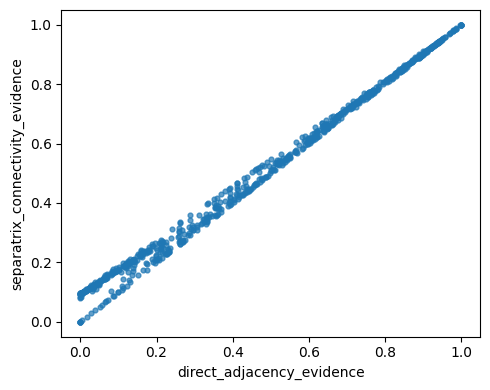

In [7]:
C_center_audit = np.asarray(bundle["C_center"], dtype=float)
candidate_result = construct_candidate_edge_table(
    transported,
    nodes_df,
    config,
    barycenter_relation=C_center_audit,
)
candidates = candidate_result.selected_edges.copy()
display(pd.Series(candidate_result.diagnostics).to_frame("value"))
display(candidates.head())
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(
    candidates["direct_adjacency_evidence"],
    candidates["separatrix_connectivity_evidence"],
    s=12,
    alpha=0.7,
)
ax.set_xlabel("direct_adjacency_evidence")
ax.set_ylabel("separatrix_connectivity_evidence")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "candidate_evidence_scatter.png", dpi=140)
plt.show()


## Initialize a maximum-support skeleton forest

Replace metric-spanner construction with a constrained Kruskal-style maximum spanning forest over `connectivity_selection_score`. Do not use `C_center`.


In [8]:
component_target = infer_target_component_count(bundle, config.target_component_count)
print(component_target)
forest_result = build_maximum_support_forest(
    candidates,
    nodes_df,
    config,
    component_target,
    effective_planarity_mode=decoded.effective_planarity_mode,
)
G_forest = forest_result.graph
display(pd.Series(forest_result.diagnostics).to_frame("value"))


ComponentTarget(count=1, source='unanimous input graph component count', input_component_counts=[1, 1, 1, 1, 1, 1, 1, 1, 1], assumption_used=False)


,value
target_component_count,1
target_source,unanimous input graph component count
final_component_count,2
forest_edge_count,433
assumption_used,False
input_component_counts,"[1, 1, 1, 1, 1, 1, 1, 1, 1]"


## Add consensus edges and remove redundant soft edges

Soft affinity can create local cliques and chords. Soft-only edges that are explained by stronger two-step or selected-path routes are treated as potentially redundant. Strongly direct-supported edges are retained.


In [9]:
augmented = augment_consensus_edges(
    G_forest,
    candidates,
    config,
    effective_planarity_mode=decoded.effective_planarity_mode,
)
repaired = local_repair_topology(
    augmented.graph,
    candidates,
    config,
    target_components=component_target.count,
    effective_planarity_mode=decoded.effective_planarity_mode,
)
G_topology = repaired.graph
print("added:", augmented.diagnostics)
print("repair objective:", repaired.objective_components)
display(repaired.edit_history.head())


KeyboardInterrupt: 

## Validate the reconstructed topology

Every barycenter node is retained. Uncovered nodes stay isolated rather than being bridged by `C_center`.


,value
original_node_count,435
final_node_count,435
missing_nodes,0
extra_nodes,0
node_retention_fraction,1.0
edge_count,662
component_count,1
cycle_rank,228
mean_degree,3.043678
max_degree,7


,node_id,support_class,degree,isolated,max_incident_direct_evidence,max_incident_separatrix_evidence,max_incident_pair_coverage


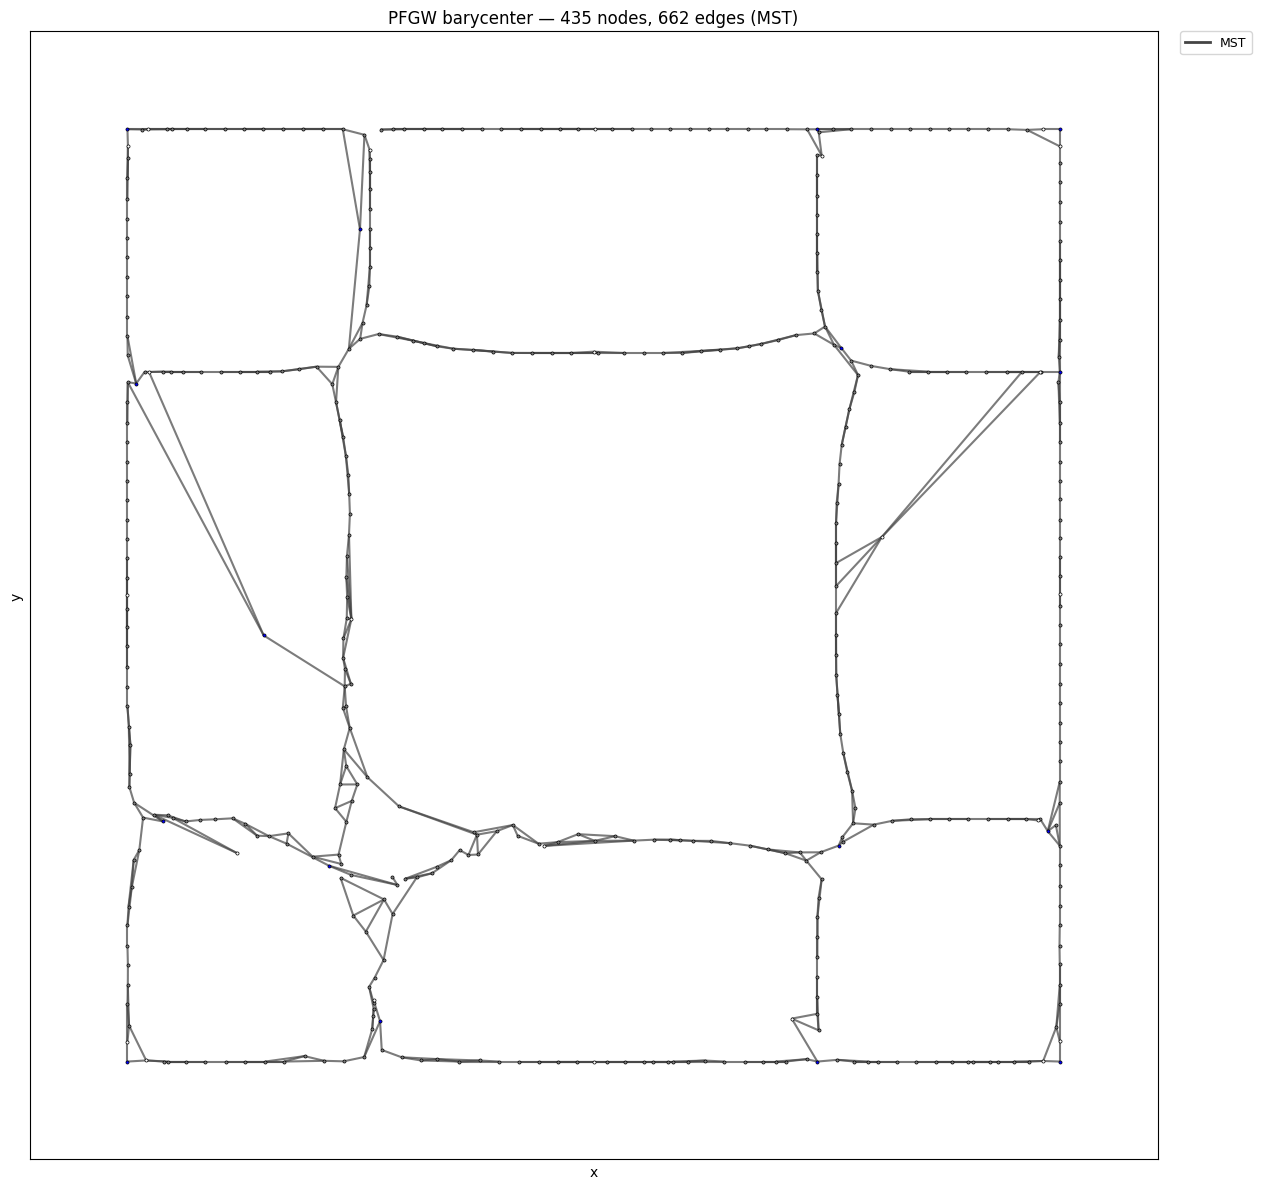

<Figure size 640x480 with 0 Axes>

In [ ]:
validation_result = validate_reconstructed_topology(
    G_topology,
    nodes_df,
    transported,
    candidates,
    config,
    effective_planarity_mode=decoded.effective_planarity_mode,
)
display(pd.Series(validation_result.metrics).to_frame("value"))
weak = validation_result.node_support_classes[
    validation_result.node_support_classes["support_class"].isin(
        ["weakly_supported", "uncovered"]
    )
]
display(weak)
from lib.msc_plotting import draw_msc_barycenter_graph
draw_msc_barycenter_graph(G_topology)
plt.gcf().savefig(FIGURES_DIR / "G_topology.png", dpi=140)
plt.show()


## Sampling-rate and parameter sensitivity

Evaluate `q in {0, 0.25, 0.5, 0.75, 1}` and `max_soft_hops in {2, 3, 4}`. Treat `q=1` as diagnostic only. Do not use `C_center` agreement to choose `(q, H)`. Configured defaults remain unless changed explicitly.

This grid re-runs transport and selection for each setting and may take several minutes on large supports.


In [ ]:
# with warnings.catch_warnings():
#     warnings.simplefilter("ignore", UserWarning)
#     sensitivity = run_q_hop_sensitivity(
#         bundle,
#         input_node_orders,
#         nodes_df,
#         config,
#         effective_planarity_mode=decoded.effective_planarity_mode,
#     )
#     sampling_sensitivity = run_sampling_mode_sensitivity(
#         bundle,
#         input_node_orders,
#         nodes_df,
#         config,
#         effective_planarity_mode=decoded.effective_planarity_mode,
#     )
# display(sensitivity)
# display(sampling_sensitivity)
# length_changed = False
# if not sampling_sensitivity.empty and "changed_edge_count" in sampling_sensitivity:
#     length_changed = bool(sampling_sensitivity["changed_edge_count"].iloc[0] > 0)


## Compare with post-hoc baselines

Baselines are evaluated only after reconstruction is fixed and do not alter the selected graph.


In [ ]:
# # Direct-only q=0 reconstruction as a labeled baseline.
# direct_config = ReconstructionConfig(
#     run_name=config.run_name,
#     reconstruction_name="direct_only_baseline",
#     hop_decay_q=0.0,
#     max_soft_hops=config.max_soft_hops,
#     enable_length_normalized_affinity=False,
# )
# direct_transported = compute_transported_separatrix_connectivity(
#     bundle, input_node_orders, direct_config, q=0.0
# )
# direct_candidates = construct_candidate_edge_table(
#     direct_transported, nodes_df, direct_config
# )
# direct_forest = build_maximum_support_forest(
#     direct_candidates.selected_edges,
#     nodes_df,
#     direct_config,
#     component_target,
#     effective_planarity_mode=decoded.effective_planarity_mode,
# )
# direct_aug = augment_consensus_edges(
#     direct_forest.graph,
#     direct_candidates.selected_edges,
#     direct_config,
#     effective_planarity_mode=decoded.effective_planarity_mode,
# )
# baseline_comparison = compare_posthoc_baselines(
#     final_graph=G_topology,
#     forest_graph=G_forest,
#     nodes=nodes_df,
#     transported=transported,
#     bundle=bundle,
#     config=config,
#     direct_only_graph=direct_aug.graph,
# )
# display(baseline_comparison)


,baseline,node_count,edge_count,component_count,cycle_rank,mean_direct_evidence,mean_separatrix_evidence,mean_pair_coverage,geometric_planarity
0,final_transported_connectivity,382,583,2,203,0.655689,0.663489,0.984276,True
1,maximum_support_forest,382,380,2,0,0.811198,0.814589,0.986010,True
2,direct_only_q0,382,572,2,192,0.665416,0.671989,0.984064,True
3,saved_G_mst,382,381,1,0,0.736736,0.740643,0.985189,True
4,C_center_threshold_baseline,382,7278,1,6897,0.064623,0.069133,0.979077,False
5,C_center_edge_count_matched,382,583,33,234,0.531634,0.541292,0.964593,False


## Optional density-based geometric routing

> Density routing changes only the geometric realization of already selected edges. The node set and adjacency come entirely from transported input connectivity.

No Morse–Smale complex of the KDE field is computed here.


In [ ]:
routed_result = None
edge_weight_semantics = "euclidean_endpoint_length"
if config.enable_density_routing:
    selected_for_density = validation_result.selected_edges.copy()
    if selected_for_density.empty:
        raise RuntimeError("No selected edges available for density routing.")
    field = build_evidence_density_field(
        nodes_df,
        selected_for_density,
        config,
        resolution=config.density_grid_resolution_candidates[0],
        bandwidth=config.density_bandwidth_candidates[0],
        mass_column="connectivity_selection_score",
    )
    routed_result = route_graph_through_density(G_topology, nodes_df, field)
    G_topology = routed_result.graph
    edge_weight_semantics = "density_routed_polyline_length"
    display(routed_result.route_statistics.head())
else:
    display(Markdown("Density routing disabled (`enable_density_routing=False`)."))


Density routing disabled (`enable_density_routing=False`).

## Post-hoc barycenter-relation consistency

`C_center` is audit-only. It must not generate candidates, rank edges, select `(q, H)`, build the forest, augment, repair, or set final graph weights.


In [ ]:
posthoc_relation_metrics = {"enabled": False}
if config.report_barycenter_relation_consistency:
    C = np.asarray(bundle["C_center"], dtype=float)
    graph_lengths = []
    relation_lengths = []
    for u, v, data in G_topology.edges(data=True):
        if np.isfinite(C[u, v]) and C[u, v] > 0:
            graph_lengths.append(float(data.get("weight", np.nan)))
            relation_lengths.append(float(C[u, v]))
    if graph_lengths:
        corr = float(np.corrcoef(graph_lengths, relation_lengths)[0, 1])
    else:
        corr = float("nan")
    posthoc_relation_metrics = {
        "enabled": True,
        "n_compared_edges": len(graph_lengths),
        "correlation_weight_vs_C_center": corr,
        "uses_barycenter_relation_for_edge_selection": False,
    }
display(posthoc_relation_metrics)


{'enabled': True,
 'n_compared_edges': 583,
 'correlation_weight_vs_C_center': 0.8143410759867027,
 'uses_barycenter_relation_for_edge_selection': False}

## Save and reload the reconstruction bundle


In [ ]:
warnings_and_fallbacks = list(validation.warnings) + list(transported.warnings)
manifest = save_reconstruction_bundle(
    OUTPUT_DIR,
    config=config,
    source_barycenter_dir=BUNDLE_DIR,
    source_metadata={
        **dict(bundle.get("meta") or {}),
        "exclude_seed": validation.exclude_seed,
    },
    nodes=nodes_df,
    transported=transported,
    candidates=candidate_result,
    forest=forest_result,
    augmented=augmented,
    repaired=repaired,
    validation=validation_result,
    sensitivity=sensitivity,
    sampling_sensitivity=sampling_sensitivity,
    baseline_comparison=baseline_comparison,
    routed=routed_result,
    posthoc_relation_metrics=posthoc_relation_metrics,
    warnings_and_fallbacks=warnings_and_fallbacks,
)
# Ensure required diagnostic CSVs exist even if save already wrote them.
transported.input_annotation_diagnostics.to_csv(
    OUTPUT_DIR / "separatrix_annotation_diagnostics.csv", index=False
)
display(Markdown(f"Saved reconstruction bundle to `{OUTPUT_DIR}`"))


Saved reconstruction bundle to `C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\VortexStreet_latest\reconstruction\transported_separatrix_connectivity_20260821T034517Z`

### Reload verification


In [ ]:
G_reloaded = load_graph_pickle(OUTPUT_DIR / "G_topology.gpickle")
reload_report = verify_reloaded_topology(
    G_reloaded,
    expected_nodes=set(nodes_df["node_id"]),
    expected_edge_count=validation_result.metrics["edge_count"],
    saved_metrics=validation_result.metrics,
    edge_weight_semantics=manifest["edge_weight_semantics"],
)
assert "G_topology.gpickle" in manifest["files_created"]
display(reload_report)
display(Markdown(f"Final output directory: `{OUTPUT_DIR}`"))


{'ok': True,
 'recomputed': {'edge_count': 583,
  'component_count': 2,
  'cycle_rank': 203,
  'final_node_count': 382}}

Final output directory: `C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\VortexStreet_latest\reconstruction\transported_separatrix_connectivity_20260821T034517Z`

## Synthetic validation tests


In [ ]:
synthetic_results = run_synthetic_separatrix_tests()
assert all(synthetic_results.values())
display(pd.Series(synthetic_results).to_frame("passed"))


,passed
A_id_parsing,True
B_multi_id_membership,True
C_same_separatrix_hop_decay,True
D_nontransitive_membership,True
E_overlapping_separatrices,True
F_multiple_common_ids,True
G_disconnected_repeated_id,True
H_binary_limit,True
I_identity_coupling,True
J_partial_coupling,True


## Final summary


In [ ]:
ann = transported.input_annotation_diagnostics
summary = f'''
### Reconstruction summary

- **method**: transported_separatrix_connectivity
- **selected q**: {config.hop_decay_q}
- **selected hop cutoff**: {config.max_soft_hops}
- **affinity mode**: {config.connectivity_affinity_mode}
- **unique separatrices / input (mean)**: {ann["unique_separatrix_id_count"].mean():.2f}
- **multi-ID edge fraction (mean)**: {ann["multi_id_edge_fraction"].mean():.3f}
- **nodes with no incident ID (sum)**: {int(ann["nodes_with_no_incident_id"].sum())}
- **disconnected per-ID subgraphs (sum)**: {int(ann["disconnected_per_id_subgraph_count"].sum())}
- **mean conditional direct-adjacency support**: {validation_result.metrics["mean_conditional_direct_adjacency_support"]}
- **mean conditional separatrix-connectivity support**: {validation_result.metrics["mean_conditional_separatrix_connectivity_support"]}
- **mean pair coverage**: {validation_result.metrics["mean_pair_coverage"]}
- **mean direct-adjacency evidence**: {validation_result.metrics["mean_direct_adjacency_evidence"]}
- **mean separatrix-connectivity evidence**: {validation_result.metrics["mean_separatrix_connectivity_evidence"]}
- **selected edges dominated by direct evidence**: {validation_result.metrics["selected_direct_dominated_fraction"]}
- **selected edges relying on soft extension**: {validation_result.metrics["selected_soft_dominated_fraction"]}
- **weakly supported nodes**: {validation_result.metrics["weakly_supported_node_count"]}
- **uncovered nodes**: {validation_result.metrics["uncovered_node_count"]}
- **final edge count**: {validation_result.metrics["edge_count"]}
- **component count**: {validation_result.metrics["component_count"]}
- **cycle rank**: {validation_result.metrics["cycle_rank"]}
- **length normalization materially changed result**: {length_changed}
- **transitive closure used**: False
- **C_center used for edge selection**: False
- **final graph**: `{OUTPUT_DIR / "G_topology.gpickle"}`
- **manifest**: `{OUTPUT_DIR / "manifest.json"}`

> The reconstructed topology is inferred from transported exact adjacency and soft connectivity along paths whose edges share one fixed recorded separatrix ID; overlapping separatrices are retained without merging their identities, and the barycenter relation is used only for optional post-hoc comparison.
'''
display(Markdown(summary))



### Reconstruction summary

- **method**: transported_separatrix_connectivity
- **selected q**: 0.1
- **selected hop cutoff**: 2
- **affinity mode**: separatrix_hop_decay
- **unique separatrices / input (mean)**: 201.00
- **multi-ID edge fraction (mean)**: 0.209
- **nodes with no incident ID (sum)**: 0
- **disconnected per-ID subgraphs (sum)**: 0
- **mean conditional direct-adjacency support**: 0.006656053429201108
- **mean conditional separatrix-connectivity support**: 0.0071272128164461025
- **mean pair coverage**: 0.9803839842950726
- **mean direct-adjacency evidence**: 0.006523408250511185
- **mean separatrix-connectivity evidence**: 0.006984408248925696
- **selected edges dominated by direct evidence**: 0.9794168096054888
- **selected edges relying on soft extension**: 0.02058319039451115
- **weakly supported nodes**: 1
- **uncovered nodes**: 0
- **final edge count**: 583
- **component count**: 2
- **cycle rank**: 203
- **length normalization materially changed result**: True
- **transitive closure used**: False
- **C_center used for edge selection**: False
- **final graph**: `C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\VortexStreet_latest\reconstruction\transported_separatrix_connectivity_20260821T034517Z\G_topology.gpickle`
- **manifest**: `C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\VortexStreet_latest\reconstruction\transported_separatrix_connectivity_20260821T034517Z\manifest.json`

> The reconstructed topology is inferred from transported exact adjacency and soft connectivity along paths whose edges share one fixed recorded separatrix ID; overlapping separatrices are retained without merging their identities, and the barycenter relation is used only for optional post-hoc comparison.
